# External data: Events
## Traffic data

The CSV files used in this notebook came from: https://data.cityofchicago.org/Transportation/Transportation-Department-Permits-Street-Closures/jdis-5sry/about_data 

Only records from 2022 up to 2026 were download from Chicago Data Portal.

Traffic data could also affect biking rythmns. To see if anomalies could be explain by traffic modifications, close streets were considered as events. 

### Cleaning

The columns were reduced from 46 to 24 to keep the more relevant information. Column names were also modified to be similar to other datasets.

Regarding records, records without coordinates or outside Chicago were discarted.

In [1]:
import pandas as pd
import geopandas as gpd
import numpy as np
import matplotlib.pyplot as plt
from geopy.geocoders import Nominatim
from geopy.extra.rate_limiter import RateLimiter

closures = pd.read_csv("data/chicago_street_closures.csv", low_memory=False)
closures.head()

,UNIQUEKEY,APPLICATIONNUMBER,APPLICATIONTYPE,APPLICATIONDESCRIPTION,WORKTYPE,WORKTYPEDESCRIPTION,APPLICATIONSTATUS,CURRENTMILESTONE,APPLICATIONSTARTDATE,APPLICATIONENDDATE,...,SUFFIX,PLACEMENT,STREETCLOSURE,DETAIL,PARKINGMETERPOSTINGORBAGGING,XCOORDINATE,YCOORDINATE,LATITUDE,LONGITUDE,LOCATION
0,19742762488264,DOT1827323,DOT_PWO,DOT Public Way Opening,GenOpening,Opening in the Public Way,Open,Inspection,08/22/2023,09/22/2023,...,AVE,NaN,Curblane,NaN,Y,1135901.0,1933664.0,41.974152,-87.775636,POINT (-87.7756362083902 41.974151646156656)
1,19782672495824,DOT1831131,DOT_PWO,DOT Public Way Opening,GenOpening,Opening in the Public Way,Closed,Cancelled,06/30/2023,07/30/2023,...,AVE,NaN,Curblane,NaN,NaN,1149839.0,1883325.0,41.835756,-87.725691,POINT (-87.7256910410382 41.835756256544364)
2,19782702495826,DOT1831133,DOT_PWO,DOT Public Way Opening,GenOpening,Opening in the Public Way,Closed,Cancelled,08/04/2023,09/04/2023,...,AVE,NaN,Curblane,NaN,NaN,1164678.0,1947441.0,42.011392,-87.669421,POINT (-87.66942130156907 42.01139178007285)
3,19782712495844,DOT1831134,DOT_PWO,DOT Public Way Opening,GenOpening,Opening in the Public Way,Open,Inspection,09/12/2023,10/12/2023,...,AVE,NaN,Curblane,NaN,Y,1180594.0,1865057.0,41.784975,-87.613405,POINT (-87.61340480579055 41.784974798240334)
4,19782742495828,DOT1831137,DOT_PWO,DOT Public Way Opening,GenOpening,Opening in the Public Way,Open,Inspection,08/01/2023,09/01/2023,...,AVE,NaN,Curblane,NaN,Y,1161287.0,1925948.0,41.952487,-87.682500,POINT (-87.68249967489386 41.95248682794845)


In [2]:
#Select and rename relevant columns
column_rename = {
    "UNIQUEKEY": "permit_id",
    "APPLICATIONNUMBER": "application_number",
    "APPLICATIONTYPE": "application_type",
    "APPLICATIONDESCRIPTION": "application_description",
    "WORKTYPE": "work_type",
    "WORKTYPEDESCRIPTION": "work_type_description",
    "APPLICATIONSTATUS": "application_status",
    "CURRENTMILESTONE": "current_milestone",
    "APPLICATIONSTARTDATE": "start_date",
    "APPLICATIONENDDATE": "end_date",
    "APPLICATIONISSUEDDATE": "issued_date",
    "APPLICATIONNAME": "application_name",
    "COMMENTS": "comments",
    "STREETNUMBERFROM": "street_number_from",
    "STREETNUMBERTO": "street_number_to",
    "DIRECTION": "direction",
    "STREETNAME": "street_name",
    "SUFFIX": "street_suffix",
    "PLACEMENT": "placement",
    "STREETCLOSURE": "street_closure",
    "DETAIL": "closure_details",
    "PARKINGMETERPOSTINGORBAGGING": "parking_meter_posting",
    "LATITUDE": "latitude",
    "LONGITUDE": "longitude"
}

closures = closures[list(column_rename.keys())].rename(columns=column_rename).copy()

#Remove records without coordinates or outside Chicago
closures = closures.dropna(subset=["latitude", "longitude"]).copy()
closures = closures[closures["latitude"].between(41.6, 42.1) & closures["longitude"].between(-88.0, -87.4)].copy()

#Convert dates into date format
date_columns = ["start_date", "end_date", "issued_date"]

for col in date_columns:
    closures[col] = pd.to_datetime(closures[col], errors="coerce")

#Selecting the time period we're working with: 2022-2025
closures = closures[(closures["start_date"] >= "2022-01-01") & (closures["end_date"] < "2026-01-01")].copy()

print("Total of records:", len(closures))
display(closures.head())

Total of records: 179972


,permit_id,application_number,application_type,application_description,work_type,work_type_description,application_status,current_milestone,start_date,end_date,...,street_number_to,direction,street_name,street_suffix,placement,street_closure,closure_details,parking_meter_posting,latitude,longitude
0,19742762488264,DOT1827323,DOT_PWO,DOT Public Way Opening,GenOpening,Opening in the Public Way,Open,Inspection,2023-08-22,2023-09-22,...,5107,N,MARMORA,AVE,NaN,Curblane,NaN,Y,41.974152,-87.775636
1,19782672495824,DOT1831131,DOT_PWO,DOT Public Way Opening,GenOpening,Opening in the Public Way,Closed,Cancelled,2023-06-30,2023-07-30,...,3136,S,KOMENSKY,AVE,NaN,Curblane,NaN,NaN,41.835756,-87.725691
2,19782702495826,DOT1831133,DOT_PWO,DOT Public Way Opening,GenOpening,Opening in the Public Way,Closed,Cancelled,2023-08-04,2023-09-04,...,1535,W,ESTES,AVE,NaN,Curblane,NaN,NaN,42.011392,-87.669421
3,19782712495844,DOT1831134,DOT_PWO,DOT Public Way Opening,GenOpening,Opening in the Public Way,Open,Inspection,2023-09-12,2023-10-12,...,6024,S,EBERHART,AVE,NaN,Curblane,NaN,Y,41.784975,-87.613405
4,19782742495828,DOT1831137,DOT_PWO,DOT Public Way Opening,GenOpening,Opening in the Public Way,Open,Inspection,2023-08-01,2023-09-01,...,3904,N,HAMILTON,AVE,NaN,Curblane,NaN,Y,41.952487,-87.682500


The dataset was also checked for duplicates, two types were considered:
- The same permit appears more than once as different records.
- Different permits refer to the same street with overlapping dates and could be consider as the same closure event.

In [2]:
# Check duplicate permit IDs and duplicate application numbers
print("Total of duplicate permit IDs:", closures["permit_id"].duplicated().sum())
print("Total of duplicate application numbers:", closures["application_number"].duplicated().sum())

#Inspecting duplicate application numbers
duplicates = closures[closures.duplicated(subset=["application_number"], keep=False)].sort_values("application_number")
duplicates.head()

Total of duplicate permit IDs: 0
Total of duplicate application numbers: 72476


,permit_id,application_number,application_type,application_description,work_type,work_type_description,application_status,current_milestone,start_date,end_date,...,street_number_to,direction,street_name,street_suffix,placement,street_closure,closure_details,parking_meter_posting,latitude,longitude
185583,1613355437439,1528853,DOT_SE,DOT Special Event Permit,Festival,Festival,Closed,Complete,2022-09-11,2022-09-11,...,3927,W,OGDEN,AVE,NaN,Full,NaN,NaN,41.852953,-87.720008
185590,1613355437440,1528853,DOT_SE,DOT Special Event Permit,Festival,Festival,Closed,Complete,2022-09-11,2022-09-11,...,2200,S,SPRINGFIELD,AVE,NaN,Full,NaN,NaN,41.852460,-87.722417
185593,1613355437441,1528853,DOT_SE,DOT Special Event Permit,Festival,Festival,Closed,Complete,2022-09-11,2022-09-11,...,2200,S,AVERS,AVE,NaN,Full,NaN,NaN,41.853046,-87.720893
185601,1613355437442,1528853,DOT_SE,DOT Special Event Permit,Festival,Festival,Closed,Complete,2022-09-11,2022-09-11,...,2200,S,HAMLIN,AVE,NaN,Curblane,No parking only both sides,NaN,41.852614,-87.720040
56938,1618520439701,1533827,DOT_SE,DOT Special Event Permit,Festival,Festival,Closed,Complete,2022-07-02,2022-07-04,...,5900,S,PAYNE,DR,NaN,Full,NaN,NaN,41.794947,-87.607540


It seems that application number can refer to different streets, so those records would be kept. Next, the dataset is analyzed to identify different records refering to the same event.

In [3]:
#Remove records without street and date 
closures_check = closures.dropna(subset=["street_name", "start_date", "end_date"]).copy()

#Define the street segment (the same street segment if all 5 values are the same)
street_columns = [
    "street_name",
    "street_suffix",
    "direction",
    "street_number_from",
    "street_number_to"
]

#Sort by street segment and start date
closures_check = closures_check.sort_values(street_columns + ["start_date", "end_date"])

# Find overlapping date ranges within each street segment
def assign_event_groups(group):

    group = group.copy()

    #Detects latest end date of all previous permits
    previous_max_end = group["end_date"].cummax().shift()

    #Registers a new event when the next permit does not overlap with the previous end date
    new_event = (previous_max_end.isna() | (group["start_date"] > previous_max_end))

    group["event_number"] = new_event.cumsum()

    return group

closures_check = (closures_check.groupby(street_columns, dropna=False, group_keys=False).apply(assign_event_groups))

# Create a unique event identifier
closures_check["event_id"] = (closures_check.groupby(street_columns + ["event_number"], dropna=False).ngroup())
closures_check = closures_check.drop(columns=["event_number"])
events = closures_check.drop_duplicates(subset="event_id").copy()

print("Total of records:", len(events))
display(events.head())

/tmp/ipykernel_1418/195262344.py:31: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  closures_check = (closures_check.groupby(street_columns, dropna=False, group_keys=False).apply(assign_event_groups))


Total of records: 167282


,permit_id,application_number,application_type,application_description,work_type,work_type_description,application_status,current_milestone,start_date,end_date,...,direction,street_name,street_suffix,placement,street_closure,closure_details,parking_meter_posting,latitude,longitude,event_id
123937,21112442718286,DOT1941074,DOT_PWO,DOT Public Way Opening,GenOpening,Opening in the Public Way,Open,Inspection,2024-04-18,2024-11-16,...,E,100TH,PL,NaN,Curblane,NaN,NaN,41.711609,-87.623430,0
20062,19146932373428,DOT1771618,DOT_PWO,DOT Public Way Opening,GenOpening,Opening in the Public Way,Open,Inspection,2023-01-06,2023-02-05,...,E,100TH,PL,NaN,Curblane,NaN,NaN,41.711649,-87.620993,1
88479,1948859462705,DOT1803390,DOT_PWO,DOT Public Way Opening,Restorat,Restoration,Open,Inspection,2023-05-01,2023-05-31,...,E,100TH,PL,NaN,Curblane,Landscape,NaN,41.711649,-87.620993,2
105865,2014337484408,DOT1864954,DOT_PWO,DOT Public Way Opening,Restorat,Restoration,Open,Inspection,2023-09-06,2023-12-29,...,E,100TH,PL,NaN,Curblane,NaN,NaN,41.711649,-87.620993,3
22371,19433842427963,DOT1798244,DOT_PWO,DOT Public Way Opening,GenOpening,Opening in the Public Way,Open,Inspection,2023-03-27,2023-04-26,...,E,100TH,PL,NaN,Curblane,NaN,NaN,41.711649,-87.620993,4


### Processing
Some of the columns in the dataset were inspected to see which records are worth focusing on.

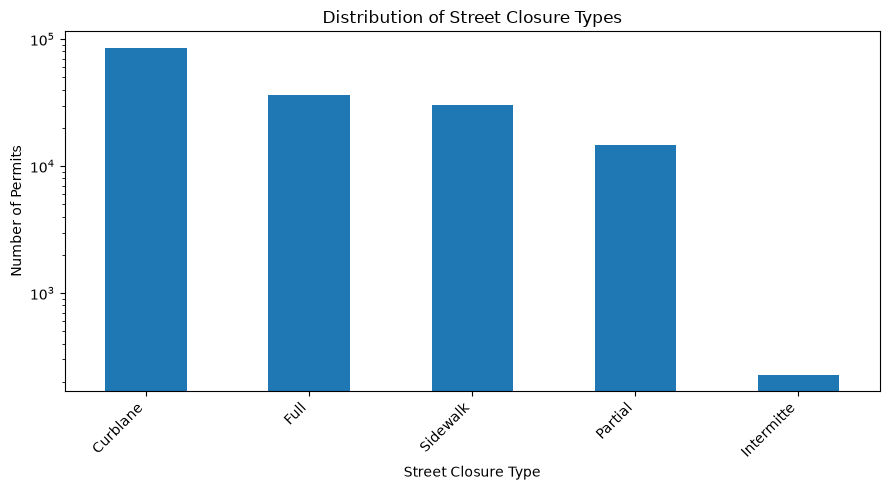

In [4]:
#Street closure distribution
events["street_closure"].value_counts().plot(kind="bar", figsize=(9, 5))

plt.title("Distribution of Street Closure Types")
plt.xlabel("Street Closure Type")
plt.ylabel("Number of Permits")
plt.xticks(rotation=45, ha="right")
plt.yscale("log")
plt.tight_layout()
plt.show()

Each different type of closure permit could produce a different effect and it could be used as a proxy for size/severity to clasify traffic events.

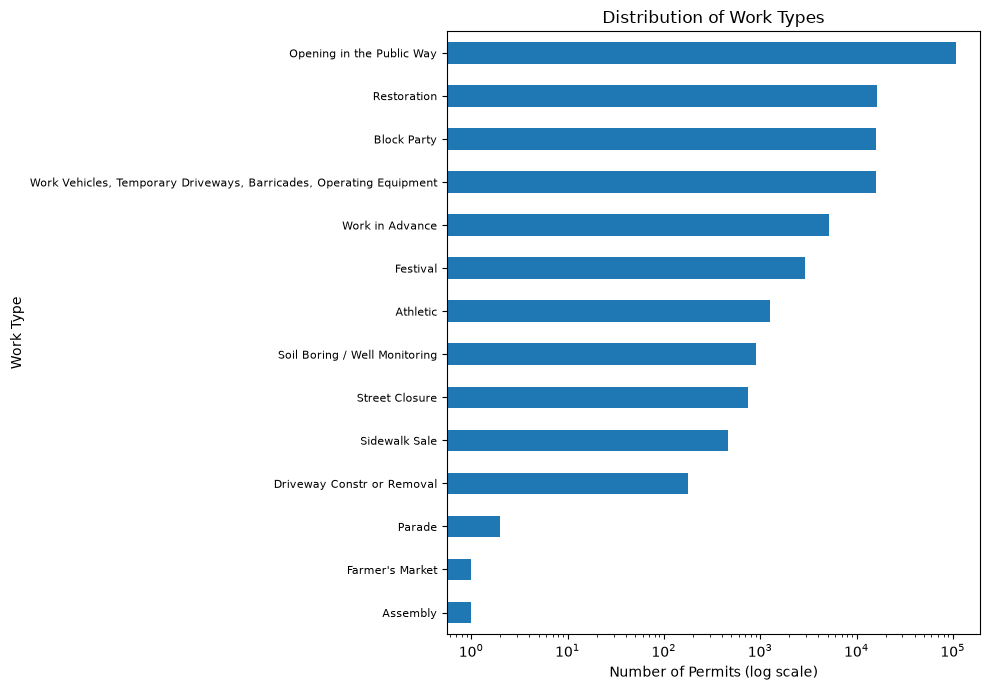

In [5]:
#Work type distribution
counts = events["work_type_description"].value_counts().sort_values()

ax = counts.plot(kind="barh", figsize=(10, 7))

ax.set_title("Distribution of Work Types")
ax.set_xlabel("Number of Permits (log scale)")
ax.set_ylabel("Work Type")
ax.set_xscale("log")
ax.tick_params(axis="y", labelsize=8)
plt.tight_layout()
plt.show()

The work type also gives more context as to why roads could be blocked and could explain differece in bike-sharing activity. As well, the analysis could initially be focus on the more frequent work types.

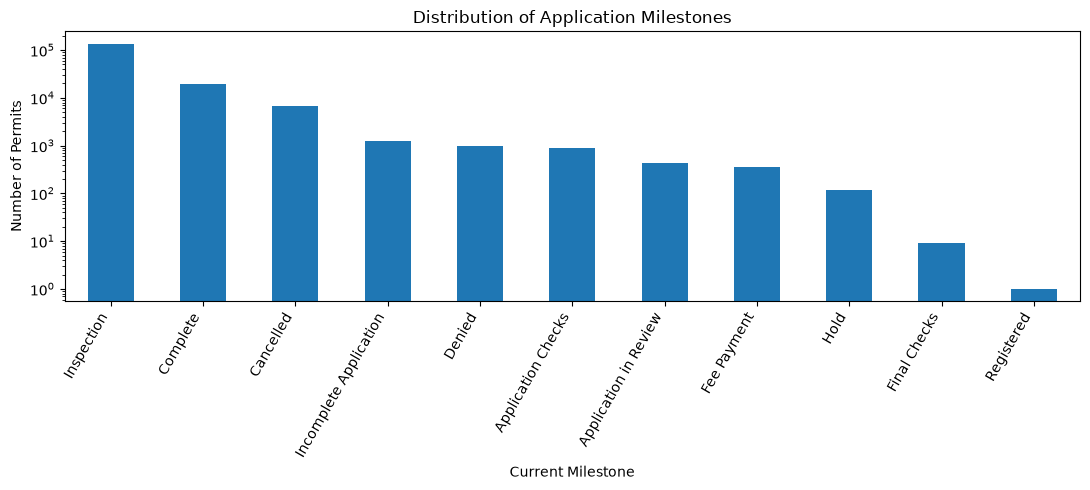

In [6]:
#Current milestone distribution
events["current_milestone"].value_counts().plot(kind="bar", figsize=(11, 5))

plt.title("Distribution of Application Milestones")
plt.xlabel("Current Milestone")
plt.ylabel("Number of Permits")
plt.xticks(rotation=60, ha="right")
plt.yscale("log")
plt.tight_layout()
plt.show()

Given the application milestones, the applications of records with "Cancelled", "Incomplete Application" or "Denied" are likely to not occur and could be ignored from the analysis. There is also a significant difference in the number of permits between milestones. Those records with low number could be removed to focus on "Inspection" and "Complete", which are the ones likely to have resulted in street closure.

In [7]:
#Filtering records based on work type
relevant_work_types = [
    "Opening in the Public Way",
    "Restoration",
    "Work Vehicles, Temporary Driveways, Barricades, Operating Equipment",
    "Street Closure",
    "Work in Advance",
    "Block Party",
    "Festival",
    "Athletic",
    "Parade"
]

closures_main = closures_check[closures_check["work_type_description"].isin(relevant_work_types)].copy()
events_main = events[events["work_type_description"].isin(relevant_work_types)].copy()

#Filtering records based on milestone
relevant_milestones = ["Inspection", "Complete"]

closures_main = closures_main[closures_main["current_milestone"].isin(relevant_milestones)].copy()
events_main = events_main[events_main["current_milestone"].isin(relevant_milestones)].copy()
closures_main.to_csv("data/chicago_closures_clean.csv", index=False)

print("Total of records after filtering:", len(closures_main))
print("Total of events after filtering:", len(events_main))

Total of records after filtering: 166842
Total of events after filtering: 155689


Now, the distribution of street closures can be compared among months and among years.

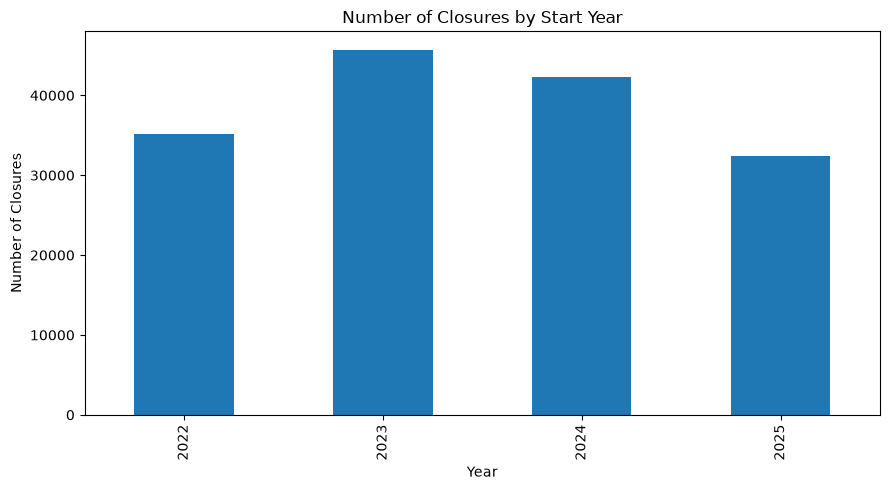

In [8]:
#Street closures counts by year
events_year = events_main.groupby(events_main["start_date"].dt.year).size()
events_year.plot(kind="bar", figsize=(9, 5))

plt.title("Number of Closures by Start Year")
plt.xlabel("Year")
plt.ylabel("Number of Closures")
plt.tight_layout()
plt.show()

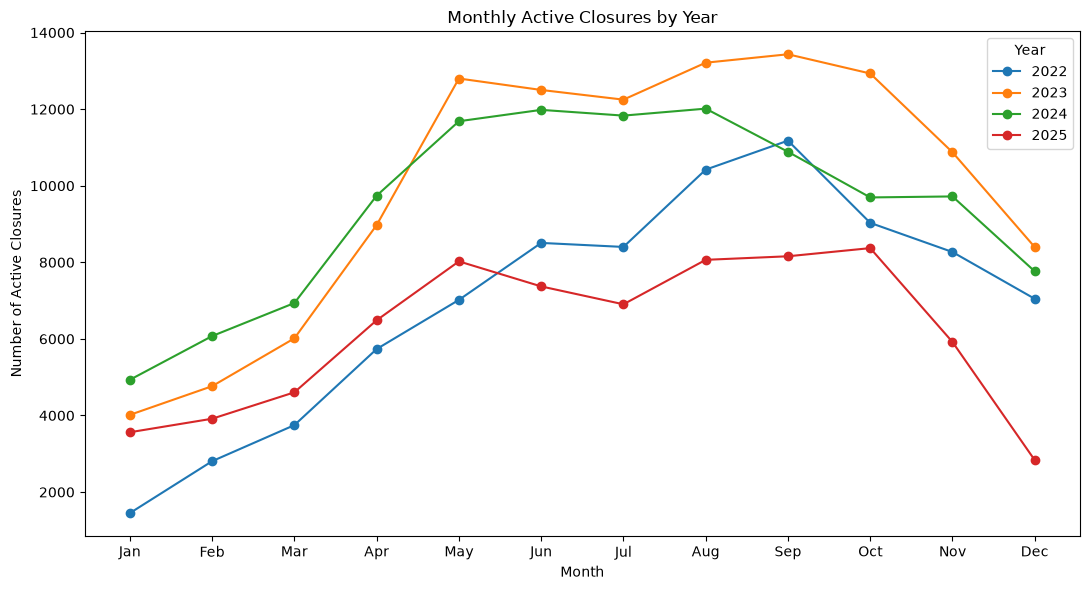

In [9]:
#Monthly closures by year
events_monthly = events_main.dropna(subset=["start_date", "end_date"]).copy()
events_monthly["month"] = events_monthly.apply(lambda row: pd.date_range(
        start=row["start_date"].to_period("M").to_timestamp(),
        end=row["end_date"].to_period("M").to_timestamp(),
        freq="MS"), axis=1)

events_monthly = events_monthly.explode("month")
events_monthly["year"] = events_monthly["month"].dt.year
events_monthly["month_number"] = events_monthly["month"].dt.month

monthly_counts = events_monthly.groupby(["year", "month_number"]).size().unstack(level="year", fill_value=0)
ax = monthly_counts.plot(kind="line", marker="o", figsize=(11, 6))

ax.set_title("Monthly Active Closures by Year")
ax.set_xlabel("Month")
ax.set_ylabel("Number of Active Closures")
ax.set_xticks(range(1, 13))
ax.set_xticklabels(["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
ax.legend(title="Year")
plt.tight_layout()
plt.show()

With the final clean and filtered dataset selected, a cell can be assigned to each closure event for future analysis. Because each event consist of several permits, a cell will be assign to each permit first and then aggregate them by event to determine which cell are associated with each event.

In [10]:
#Load original geographic zones
zones = gpd.read_file("data/zones.geojson")

#Load mapping between original zones and hybrid cells
zone_to_cell = pd.read_csv("data/zone_to_cell.csv")

#Generate cells
cells_map = zones.merge(zone_to_cell, on="zone_id", how="left")
cells_map = cells_map.to_crs(epsg=26916)
cells_map = cells_map.dissolve(by="cell_id").reset_index() #Combines the geometries belonging to the same cell
cells_for_join = cells_map[["cell_id", "geometry"]].copy()
cells_for_join = cells_for_join.reset_index(drop=True)

#Convert streets (from permits) into geographic points
permits = closures_main[["permit_id", "street_name", "street_suffix", "latitude", "longitude", "event_id", "start_date", "end_date"]].drop_duplicates().copy()
permits = permits.copy().reset_index(drop=True)
permits["permit_row_id"] = range(len(permits))

permits["latitude"] = pd.to_numeric(permits["latitude"], errors="coerce")
permits["longitude"] = pd.to_numeric(permits["longitude"], errors="coerce") #Make sure the coordinates are numeric

permits_geo = gpd.GeoDataFrame(permits.dropna(subset=["latitude", "longitude"]).copy(), geometry=gpd.points_from_xy(
        permits.dropna(subset=["latitude", "longitude"])["longitude"],
        permits.dropna(subset=["latitude", "longitude"])["latitude"]), crs="EPSG:4326")
permits_geo = permits_geo.to_crs(cells_map.crs)

#Assign a cell to each permit
permits = gpd.sjoin(permits_geo, cells_for_join, how="left", predicate="within")
permits = permits.drop(columns=["geometry", "index_right"])

#Inspect data
print("Total permits:", len(permits_geo))
print("Permits without cell:", permits["cell_id"].isna().sum())
permits.tail()

Total permits: 166842
Permits without cell: 174


,permit_id,street_name,street_suffix,latitude,longitude,event_id,start_date,end_date,permit_row_id,cell_id
166837,21200292726187,YORK,RD,41.972054,-87.939863,167275,2024-05-07,2024-06-06,166837,NaN
166838,21580752770108,YORK,RD,41.972225,-87.939568,167276,2024-07-22,2024-10-30,166838,9.0
166839,21703592785473,YORK,RD,41.973337,-87.939568,167277,2024-08-13,2024-10-31,166839,9.0
166840,18926862342572,YORK,RD,41.986392,-87.939671,167280,2022-11-14,2022-12-31,166840,9.0
166841,21469602757728,YORK,RD,41.987105,-87.939975,167281,2024-07-01,2024-10-30,166841,NaN


The unmatched permits are going to be plot to determined what to do with them.

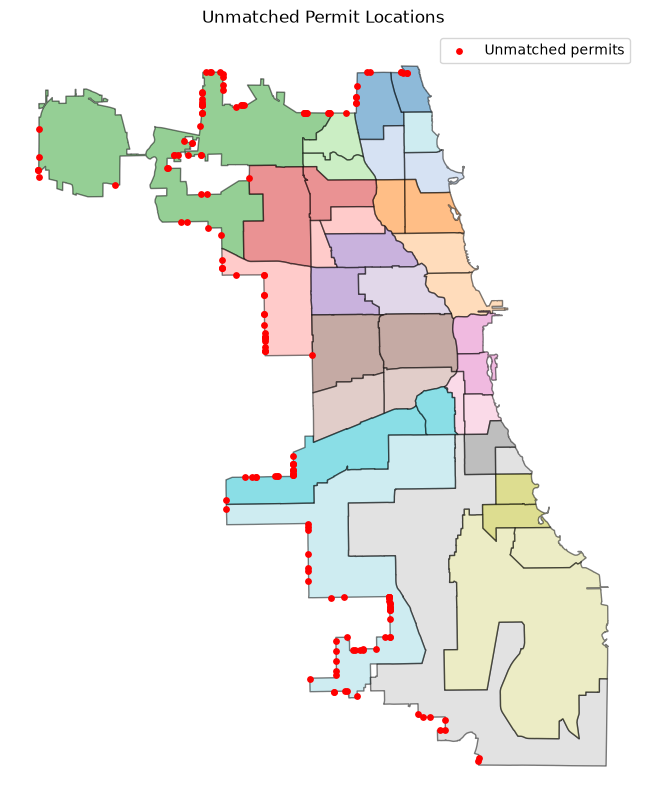

In [11]:
# Permits that were assigned to a cell
matched = permits[permits["cell_id"].notna()][["permit_row_id", "cell_id"]].copy()

# Find permits that still need a cell
unmatched_points = permits_geo[~permits_geo["permit_row_id"].isin(matched["permit_row_id"])].copy()

fig, ax = plt.subplots(figsize=(12, 10))

#Plot the spatial cells
cells_map.plot(ax=ax, column="cell_id", cmap="tab20", edgecolor="black", alpha=0.5)

#Plot unmatched points on top
unmatched_points.plot(ax=ax, color="red", markersize=15, label="Unmatched permits", zorder=5)

ax.set_title("Unmatched Permit Locations")
ax.legend()
ax.set_axis_off()

plt.show()

As it seem the points were not assign to a cell due to falling on the boundaries, unmatched points will be assigned to the nearest cell within maximum distance of 5 meters. If there are unmatched points afterwards they would be considered outside of the study grid and they will be removed.

In [16]:
#Calculate nearest cells
cells_for_join["rep_point"] = (cells_for_join.geometry.representative_point())
nearest = gpd.sjoin_nearest(unmatched_points, cells_for_join, how="left", max_distance=5, distance_col="grid_distance")

#Assign unmatched points to the nearest cell
nearest["rep_distance"] = nearest.apply(lambda row: row.geometry.distance(row.rep_point)
    if pd.notna(row["cell_id"]) else float("inf"), axis=1)
nearest = (nearest.sort_values(["permit_row_id", "rep_distance", "cell_id"]).drop_duplicates("permit_row_id"))
nearest = nearest[nearest["cell_id"].notna()][["permit_row_id", "cell_id"]]

#Transfer all assignments to the permits
cell_assignments = pd.concat([matched, nearest], ignore_index=True)

permits = permits.merge(cell_assignments, on="permit_row_id",how="left")

print("Total permit records:", len(permits))
print("Permits without a cell:", permits["cell_id"].isna().sum())
print("Duplicate permit rows:", permits["permit_row_id"].duplicated().sum())

permits = permits.dropna(subset=["cell_id"]).copy()
print("Total permit records after removing unmatched points:", len(permits))

Total permit records: 166842
Permits without a cell: 161
Duplicate permit rows: 0
Total permit records after removing unmatched points: 166681


With all the permits being asigned to a cell, it can be known which cell are associated with each potential event.

In [30]:
#Associate events and cells
event_cells = (permits.dropna(subset=["cell_id"]).groupby(["event_id", "cell_id"])
    .agg(permit_count=("permit_id", "count"), start_date=("start_date", "min"), end_date=("end_date", "max"))
    .reset_index())

#Inspect results
print("Total permit records:", len(permits))
print("Total candidate events with spatial assignments:", event_cells["event_id"].nunique())
print("Total event-cell combinations:", len(event_cells))
print("Unique cells containing events:", event_cells["cell_id"].nunique())

#Cells affected per event
cells_per_event = (event_cells.groupby("event_id")["cell_id"].nunique())
print("Number of cells affected per event:", cells_per_event.mean())

Total permit records: 166681
Total candidate events with spatial assignments: 157477
Total event-cell combinations: 157477
Unique cells containing events: 37
Number of cells affected per event: 1.0


Now, the events distribution of events per cell can be analyzed. 

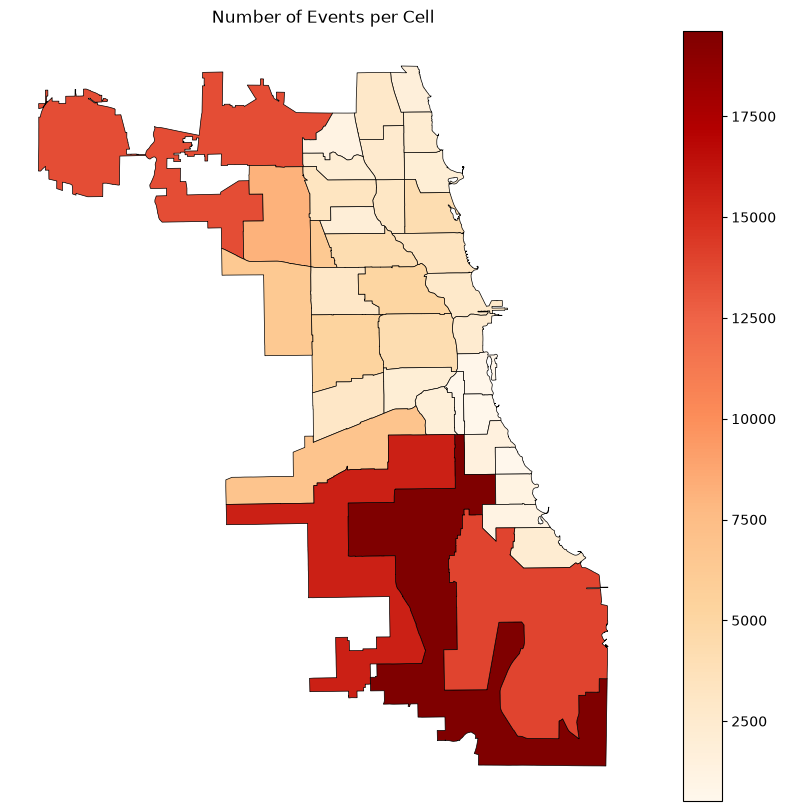

In [23]:
#Calculate and plot events per cell
events_per_cell = (event_cells.groupby("cell_id")["event_id"].nunique().reset_index(name="number_of_events"))

cells_events = cells_map.merge(events_per_cell, on="cell_id", how="left")
cells_events["number_of_events"] = (cells_events["number_of_events"].fillna(0))

fig, ax = plt.subplots(figsize=(12, 10))
cells_events.plot(column="number_of_events", cmap="OrRd", linewidth=0.5, edgecolor="black", legend=True, ax=ax, missing_kwds={"color": "lightgrey"})

ax.set_title("Number of Events per Cell")
ax.set_axis_off()

plt.show()